# Linear Regression 2.2 – Goals per team per FIFA World Cup 2026 match

208 rows (104 matches × 2 teams), 8 pre-match variables.

In [1]:
# Libraries and settings
import hashlib
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
from sklearn.model_selection import GroupShuffleSplit, GroupKFold, KFold, cross_validate
from sklearn.linear_model import LinearRegression, RidgeCV, LassoCV, ElasticNetCV, PoissonRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.dummy import DummyRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.feature_selection import SequentialFeatureSelector
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

BLUE, ORANGE, GREY = "#2a78d6", "#eb6834", "#8a8984"
sns.set_theme(style="whitegrid", font_scale=0.95)
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.width", 160)
SEED = 42

## 1. Data


In [2]:
# Load data and record file hashes
PATH = ""
FILES = ["matches", "match_team_stats", "teams", "venues", "tournament_stages", "squads_and_players"]
raw = {f: pd.read_csv(PATH + f + ".csv") for f in FILES}
for f in FILES:
    print(f"{f:<31} rows={len(raw[f]):>5}  sha256={hashlib.sha256(open(PATH + f + '.csv', 'rb').read()).hexdigest()[:16]}")

matches, team_stats, teams, venues, stages = (raw[f] for f in FILES[:5])
players = raw["squads_and_players"]
print("\nMatches:", len(matches), "| status:", matches["status"].unique().tolist(),
      "| team-stat rows per match:", team_stats.groupby("match_id").size().unique().tolist())
print("Match dates by stage:", matches.groupby("stage_id")["date"].agg(["min", "max"]).to_dict("index"))

matches                         rows=  104  sha256=83d167fa78d6683b
match_team_stats                rows=  208  sha256=9d2b99767cff0d38
teams                           rows=   48  sha256=b694972c63f48236
venues                          rows=   16  sha256=8f62397df67318f2
tournament_stages               rows=    7  sha256=d77cfa0dc437ae74
squads_and_players              rows= 1248  sha256=70e860e060954583

Matches: 104 | status: ['Completed'] | team-stat rows per match: [2]
Match dates by stage: {1: {'min': '2026-06-11', 'max': '2026-06-28'}, 2: {'min': '2026-06-29', 'max': '2026-07-04'}, 3: {'min': '2026-07-04', 'max': '2026-07-07'}, 4: {'min': '2026-07-09', 'max': '2026-07-12'}, 5: {'min': '2026-07-14', 'max': '2026-07-15'}, 6: {'min': '2026-07-18', 'max': '2026-07-18'}, 7: {'min': '2026-07-19', 'max': '2026-07-19'}}




## 2. Wrangling

In [3]:
# Build the 208-row dataset (prev_* use earlier matches only)
cols = ["match_id", "date", "stage_id", "venue_id", "team_id", "opponent_id", "goals", "xg_conceded"]
home = matches[["match_id", "date", "stage_id", "venue_id", "home_team_id", "away_team_id", "home_score", "away_xg"]]
away = matches[["match_id", "date", "stage_id", "venue_id", "away_team_id", "home_team_id", "away_score", "home_xg"]]
df = pd.concat([home.set_axis(cols, axis=1), away.set_axis(cols, axis=1)], ignore_index=True)
df = df.merge(team_stats[["match_id", "team_id", "possession_pct", "total_shots", "corners"]], on=["match_id", "team_id"])
df = df.sort_values(["team_id", "date", "match_id"])

prior = {"possession_pct": 50, "total_shots": 12, "corners": 4.5, "xg_conceded": 1.2}
for c, val in prior.items():
    df["prev_" + c] = df.groupby("team_id")[c].transform(lambda s: s.shift(1).expanding().mean()).fillna(val)
df["first_match"] = df.groupby("team_id").cumcount() == 0

players["age"] = (pd.Timestamp("2026-06-11") - pd.to_datetime(players["date_of_birth"])).dt.days / 365.25
squad = players.groupby("team_id").agg(squad_avg_age=("age", "mean"), squad_total_caps=("caps", "sum"))
squad["fwd_intl_goals"] = players[players["position"] == "FWD"].groupby("team_id")["goals"].sum()

opp = df[["match_id", "team_id", "prev_xg_conceded"]].set_axis(["match_id", "opponent_id", "opp_prev_xg_conceded"], axis=1)
df = (df.merge(squad, on="team_id").merge(venues[["venue_id", "elevation_meters"]], on="venue_id")
        .merge(opp, on=["match_id", "opponent_id"]))
names = teams.set_index("team_id")["team_name"]
df["team"], df["opponent"] = df["team_id"].map(names), df["opponent_id"].map(names)
df["stage"] = df["stage_id"].map(stages.set_index("stage_id")["stage_name"])
df = df.rename(columns={"prev_possession_pct": "prev_possession", "prev_total_shots": "prev_shots",
                        "elevation_meters": "venue_elevation"}).sort_values(["match_id", "team"]).reset_index(drop=True)

FEATURES = ["squad_avg_age", "squad_total_caps", "fwd_intl_goals", "prev_possession",
            "prev_shots", "prev_corners", "opp_prev_xg_conceded", "venue_elevation"]
final = df[["match_id", "date", "stage", "team", "opponent"] + FEATURES + ["goals"]].round(3)
assert len(final) == 208 and len(FEATURES) == 8 and final.isna().sum().sum() == 0
assert (final["match_id"].values[::2] == final["match_id"].values[1::2]).all()
final.to_csv("fifa_wc2026_lr22_dataset.csv", index=False)

print(df.loc[df["team"] == "Mexico", ["date", "possession_pct", "prev_possession"]].head(3).to_string(index=False))
final.head()

      date  possession_pct  prev_possession
2026-06-11              57             50.0
2026-06-18              49             57.0
2026-06-24              50             53.0


,match_id,date,stage,team,opponent,squad_avg_age,squad_total_caps,fwd_intl_goals,prev_possession,prev_shots,prev_corners,opp_prev_xg_conceded,venue_elevation,goals
0,1,2026-06-11,Group Stage,Mexico,South Africa,27.901,1237,75,50.0,12.0,4.5,1.2,2200,2
1,1,2026-06-11,Group Stage,South Africa,Mexico,26.808,538,33,50.0,12.0,4.5,1.2,2200,0
2,2,2026-06-11,Group Stage,Czechia,South Korea,27.621,738,53,50.0,12.0,4.5,1.2,1566,1
3,2,2026-06-11,Group Stage,South Korea,Czechia,28.066,974,75,50.0,12.0,4.5,1.2,1566,2
4,3,2026-06-12,Group Stage,Bosnia and Herzegovina,Canada,26.456,613,85,50.0,12.0,4.5,1.2,76,1


## 3. EDA

In [4]:
# Summary statistics
desc = final[FEATURES + ["goals"]].describe().T
desc["skew"] = final[FEATURES + ["goals"]].skew()
desc.round(2)

,count,mean,std,min,25%,50%,75%,max,skew
squad_avg_age,208.0,27.87,1.09,25.85,26.97,27.65,28.61,30.43,0.45
squad_total_caps,208.0,910.62,220.01,531.00,758.00,853.00,1032.00,1586.00,0.72
fwd_intl_goals,208.0,78.08,40.60,18.00,44.50,75.00,98.00,188.00,0.97
prev_possession,208.0,49.80,9.47,23.50,46.63,50.00,56.36,74.00,-0.73
prev_shots,208.0,12.85,4.36,3.00,11.00,12.00,14.67,31.00,1.11
prev_corners,208.0,4.68,2.12,0.50,3.50,4.50,5.36,14.00,1.42
opp_prev_xg_conceded,208.0,1.24,0.60,0.30,0.89,1.20,1.36,4.82,2.07
venue_elevation,208.0,259.66,537.02,2.00,7.75,30.00,264.00,2200.00,2.81
goals,208.0,1.48,1.39,0.00,0.00,1.00,2.00,7.00,1.15


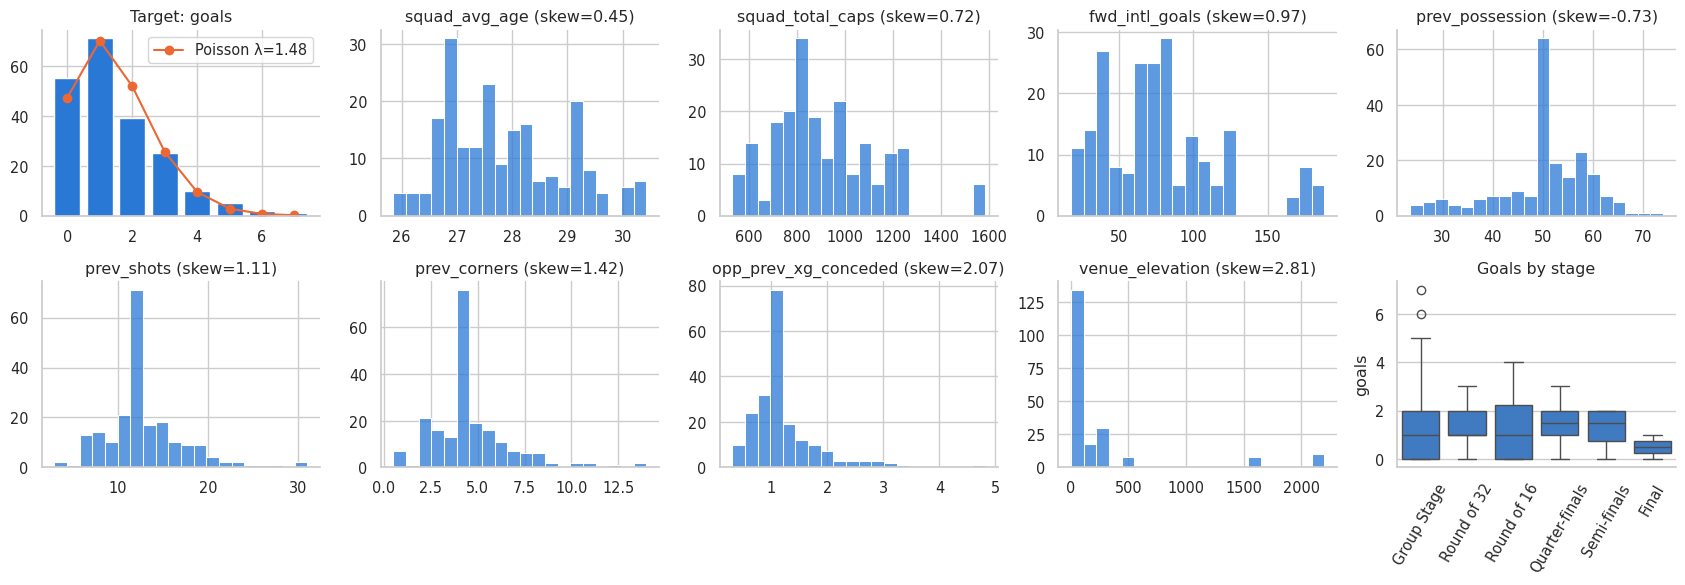

Goals: mean=1.48, variance=1.94


In [5]:
# Distributions
fig, axes = plt.subplots(2, 5, figsize=(17, 6))
counts = final["goals"].value_counts().sort_index()
axes[0, 0].bar(counts.index, counts.values, color=BLUE)
axes[0, 0].plot(counts.index, stats.poisson.pmf(counts.index, final["goals"].mean()) * 208, "o-", color=ORANGE,
                label=f"Poisson λ={final['goals'].mean():.2f}")
axes[0, 0].set_title("Target: goals"); axes[0, 0].legend()
for ax, col in zip(axes.ravel()[1:9], FEATURES):
    sns.histplot(final[col], bins=20, color=BLUE, ax=ax)
    ax.set(title=f"{col} (skew={final[col].skew():.2f})", xlabel="", ylabel="")
order = ["Group Stage", "Round of 32", "Round of 16", "Quarter-finals", "Semi-finals", "Third Place Play-off", "Final"]
sns.boxplot(data=final, x="stage", y="goals", order=[s for s in order if s in set(final["stage"])], color=BLUE, ax=axes[1, 4])
axes[1, 4].set(title="Goals by stage", xlabel=""); axes[1, 4].tick_params(axis="x", rotation=60)
plt.tight_layout(); plt.show()
print(f"Goals: mean={final['goals'].mean():.2f}, variance={final['goals'].var():.2f}")

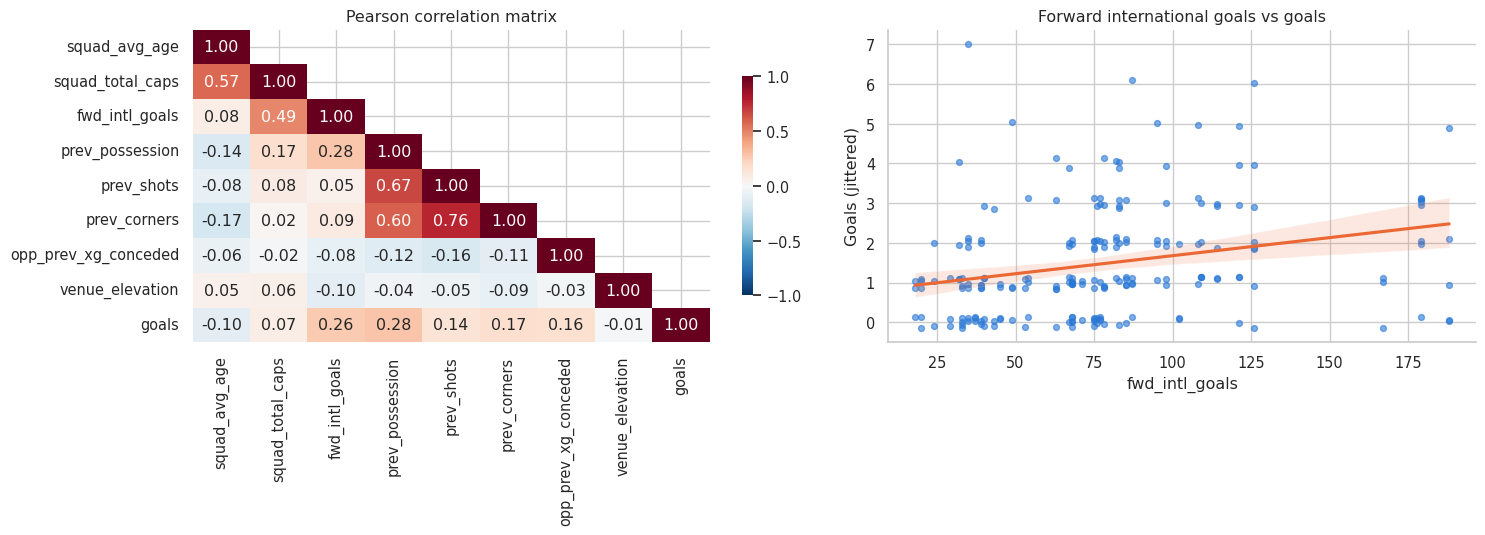

,feature,pearson_r,p,spearman_rho,p_spearman,VIF
3,prev_possession,0.284,0.000,0.287,0.000,2.158
2,fwd_intl_goals,0.265,0.000,0.331,0.000,1.567
5,prev_corners,0.169,0.014,0.202,0.003,2.514
6,opp_prev_xg_conceded,0.158,0.023,0.187,0.007,1.052
4,prev_shots,0.136,0.050,0.177,0.011,3.019
0,squad_avg_age,-0.103,0.140,-0.071,0.306,1.771
1,squad_total_caps,0.072,0.302,0.146,0.036,2.249
7,venue_elevation,-0.008,0.907,0.036,0.603,1.039


In [6]:
# Correlation, VIF and forward goals vs goals
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5), gridspec_kw={"width_ratios": [1.1, 1]})
corr = final[FEATURES + ["goals"]].corr()
sns.heatmap(corr, mask=np.triu(np.ones_like(corr, bool), 1), annot=True, fmt=".2f", cmap="RdBu_r",
            vmin=-1, vmax=1, ax=axes[0], cbar_kws={"shrink": 0.7})
axes[0].set_title("Pearson correlation matrix")
x = final["fwd_intl_goals"]
axes[1].scatter(x, final["goals"] + np.random.default_rng(0).uniform(-.15, .15, 208), s=18, alpha=.6, color=BLUE)
sns.regplot(x=x, y=final["goals"], scatter=False, color=ORANGE, ax=axes[1])
axes[1].set(title="Forward international goals vs goals", xlabel="fwd_intl_goals", ylabel="Goals (jittered)")
plt.tight_layout(); plt.show()

X_std = (final[FEATURES] - final[FEATURES].mean()) / final[FEATURES].std()
rows = []
for c in FEATURES:
    r, p = stats.pearsonr(final[c], final["goals"])
    rho, p_s = stats.spearmanr(final[c], final["goals"])
    vif = 1 / (1 - LinearRegression().fit(X_std.drop(columns=c), X_std[c]).score(X_std.drop(columns=c), X_std[c]))
    rows.append([c, r, p, rho, p_s, vif])
pd.DataFrame(rows, columns=["feature", "pearson_r", "p", "spearman_rho", "p_spearman", "VIF"]).sort_values(
    "pearson_r", key=abs, ascending=False).round(3)

In [7]:
# t-test and ANOVA
high, low = final.loc[final["venue_elevation"] > 1000, "goals"], final.loc[final["venue_elevation"] <= 1000, "goals"]
print(f"Altitude (Welch t-test): >1000 m mean={high.mean():.2f} vs other={low.mean():.2f}, "
      f"p={stats.ttest_ind(high, low, equal_var=False).pvalue:.3f}")
tertile = pd.qcut(final["fwd_intl_goals"], 3, labels=["Low", "Mid", "High"])
groups = [final.loc[tertile == t, "goals"] for t in ["Low", "Mid", "High"]]
print("Mean goals by forward-goals tertile:", [round(float(g.mean()), 2) for g in groups])
print(f"ANOVA p={stats.f_oneway(*groups).pvalue:.2e} | Kruskal-Wallis p={stats.kruskal(*groups).pvalue:.2e}")

Altitude (Welch t-test): >1000 m mean=1.39 vs other=1.49, p=0.731
Mean goals by forward-goals tertile: [1.05, 1.45, 1.96]
ANOVA p=4.38e-04 | Kruskal-Wallis p=1.26e-04




## 4. Modelling
- Train on group stage (144 rows), test on knockouts (64 rows).
- CV grouped by match: 5 folds × 10 repeats; tuning done inside each fold.

In [9]:
# Train/test split (group stage / knockouts) and baseline models
X, y, match = final[FEATURES], final["goals"], final["match_id"]
group_stage = (final["stage"] == "Group Stage").values
X_train, X_test, y_train, y_test = X[group_stage], X[~group_stage], y[group_stage], y[~group_stage]
m_train = match[group_stage]
assert not set(m_train) & set(match[~group_stage])
print(f"Train: {len(y_train)} rows / {m_train.nunique()} matches | Test: {len(y_test)} rows / {match[~group_stage].nunique()} matches")

def grouped_cv(groups, repeats=10):
    return [s for r in range(repeats) for s in GroupKFold(5, shuffle=True, random_state=r).split(groups, groups=groups)]

class PairKFold(KFold):
    def split(self, X, y=None, groups=None):
        return GroupKFold(self.n_splits).split(X, groups=np.arange(len(X)) // 2)

cv, inner = grouped_cv(m_train), PairKFold(5)
log = lambda X: X.assign(squad_total_caps=np.log(X["squad_total_caps"]), fwd_intl_goals=np.log1p(X["fwd_intl_goals"]), prev_shots=np.log(X["prev_shots"]),
                         prev_corners=np.log1p(X["prev_corners"]), opp_prev_xg_conceded=np.log(X["opp_prev_xg_conceded"]))
Xtr_log, Xte_log = log(X_train), log(X_test)
results = []

SCORING = ["neg_root_mean_squared_error", "neg_mean_absolute_error", "r2"]

def evaluate(name, model, Xtr):
    add_result(name, cross_validate(model, Xtr, y_train, cv=cv, scoring=SCORING))

def add_result(name, s):
    results.append({"model": name, "RMSE": -s["test_neg_root_mean_squared_error"].mean(),
                    "SE": s["test_neg_root_mean_squared_error"].std() / np.sqrt(len(cv)),
                    "MAE": -s["test_neg_mean_absolute_error"].mean(), "R2": s["test_r2"].mean()})

evaluate("0. Naive mean", DummyRegressor(), X_train)
evaluate("1. OLS – raw 8 features", LinearRegression(), X_train)
evaluate("2. OLS – log of skewed features", LinearRegression(), Xtr_log)
evaluate("2b. OLS – log + interaction + altitude flag", LinearRegression(),
         Xtr_log.assign(fwdgoals_x_oppxg=Xtr_log["fwd_intl_goals"] * Xtr_log["opp_prev_xg_conceded"],
                        high_alt=(Xtr_log["venue_elevation"] > 1000).astype(int)))
pd.DataFrame(results).round(3)

Train: 144 rows / 72 matches | Test: 64 rows / 32 matches


,model,RMSE,SE,MAE,R2
0,0. Naive mean,1.456,0.030,1.177,-0.035
1,1. OLS – raw 8 features,1.413,0.032,1.078,0.010
2,2. OLS – log of skewed features,1.378,0.031,1.069,0.062
3,2b. OLS – log + interaction + altitude flag,1.393,0.031,1.077,0.033


OLS coefficients with normal and match-clustered standard errors:

In [10]:
# OLS table with clustered standard errors
Xm = np.column_stack([np.ones(len(X_train)), ((X_train - X_train.mean()) / X_train.std()).values])
beta, *_ = np.linalg.lstsq(Xm, y_train.values, rcond=None)
e = y_train.values - Xm @ beta
n, k, G = *Xm.shape, m_train.nunique()
bread = np.linalg.inv(Xm.T @ Xm)
se = np.sqrt(np.diag(e @ e / (n - k) * bread))
meat = sum(np.outer(Xm[i].T @ e[i], Xm[i].T @ e[i]) for i in m_train.reset_index(drop=True).groupby(m_train.values).indices.values())
se_cl = np.sqrt(np.diag(bread @ meat @ bread) * G / (G - 1) * (n - 1) / (n - k))
r2 = 1 - e @ e / ((y_train - y_train.mean()) ** 2).sum()
print(f"In-sample R² = {r2:.3f}, adjusted R² = {1 - (1 - r2) * (n - 1) / (n - k):.3f}")
pd.DataFrame({"coef": beta, "se": se, "p": 2 * stats.t.sf(abs(beta / se), n - k),
              "se_clustered": se_cl, "p_clustered": 2 * stats.t.sf(abs(beta / se_cl), G - 1)},
             index=["intercept"] + FEATURES).round(4)

In-sample R² = 0.181, adjusted R² = 0.133


,coef,se,p,se_clustered,p_clustered
intercept,1.4931,0.1139,0.0000,0.1092,0.0000
squad_avg_age,-0.0712,0.1546,0.6461,0.1205,0.5568
squad_total_caps,-0.1153,0.1721,0.5039,0.1418,0.4186
fwd_intl_goals,0.3577,0.1395,0.0114,0.1307,0.0078
prev_possession,0.4159,0.1564,0.0088,0.1496,0.0070
prev_shots,-0.1784,0.1934,0.3580,0.2251,0.4308
prev_corners,0.1968,0.1796,0.2751,0.2006,0.3298
opp_prev_xg_conceded,0.2435,0.1167,0.0388,0.1489,0.1064
venue_elevation,0.0430,0.1168,0.7134,0.0793,0.5890


Forward goals and previous possession are significant (clustered p < 0.01). Log transform improves CV RMSE (1.413 → 1.378).

### Feature selection and regularisation

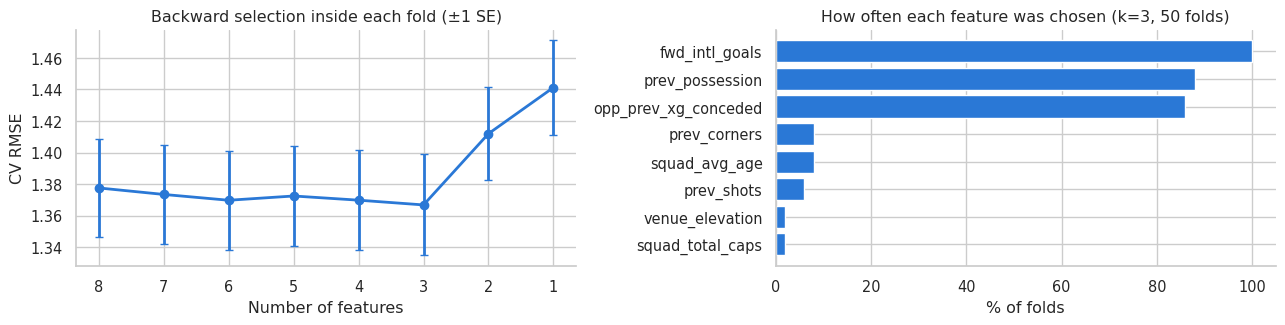

{8: 1.378, 7: 1.373, 6: 1.37, 5: 1.372, 4: 1.37, 3: 1.367, 2: 1.412, 1: 1.441}


In [11]:
# In-fold feature selection and other models
sel, picked = [], None
for k in range(8, 0, -1):
    model = LinearRegression() if k == 8 else make_pipeline(
        SequentialFeatureSelector(LinearRegression(), n_features_to_select=k, direction="backward",
                                  cv=inner, scoring="neg_root_mean_squared_error"), LinearRegression())
    s = cross_validate(model, Xtr_log, y_train, cv=cv, scoring=SCORING, return_estimator=(k == 3))
    sel.append([k, -s["test_neg_root_mean_squared_error"].mean(), s["test_neg_root_mean_squared_error"].std() / np.sqrt(len(cv))])
    if k in (1, 3):
        add_result(f"3{'' if k == 3 else 'b'}. OLS – log + in-fold backward selection (k={k})", s)
    if k == 1:
        top1 = Xtr_log.columns[SequentialFeatureSelector(LinearRegression(), n_features_to_select=1, direction="backward",
                               cv=inner, scoring="neg_root_mean_squared_error").fit(Xtr_log, y_train).get_support()][0]
    if k == 3:
        picked = pd.Series([f for est in s["estimator"] for f in Xtr_log.columns[est[0].get_support()]]).value_counts() / len(cv)
sel = pd.DataFrame(sel, columns=["k", "cv_RMSE", "SE"])

fig, axes = plt.subplots(1, 2, figsize=(13, 3.4))
axes[0].errorbar(sel["k"], sel["cv_RMSE"], yerr=sel["SE"], fmt="o-", color=BLUE, lw=2, capsize=3)
axes[0].invert_xaxis(); axes[0].set(title="Backward selection inside each fold (±1 SE)", xlabel="Number of features", ylabel="CV RMSE")
axes[1].barh(picked.index[::-1], picked.values[::-1] * 100, color=BLUE)
axes[1].set(title="How often each feature was chosen (k=3, 50 folds)", xlabel="% of folds")
plt.tight_layout(); plt.show()
print(dict(zip(sel["k"], sel["cv_RMSE"].round(3))))

alphas = np.logspace(-3, 3, 50)
models = {
    "4. Ridge – log, all 8": make_pipeline(StandardScaler(), RidgeCV(alphas=alphas, cv=inner)),
    "5. Lasso – log, all 8": make_pipeline(StandardScaler(), LassoCV(alphas=alphas, cv=inner)),
    "6. Elastic Net – log, all 8": make_pipeline(StandardScaler(), ElasticNetCV(alphas=alphas, l1_ratio=[.2, .5, .8], cv=inner)),
    "7. Poisson regression – log, all 8": make_pipeline(StandardScaler(), PoissonRegressor(alpha=0.5, max_iter=1000)),
    "8. Random forest – all 8": RandomForestRegressor(300, min_samples_leaf=10, random_state=SEED),
}
for name, m in models.items():
    evaluate(name, m, X_train if "forest" in name else Xtr_log)

Selection curve is flat from 8 to 3 features and worse below 3, so several variables are needed. Regularisation works best (Lasso CV RMSE 1.362).

### Model comparison

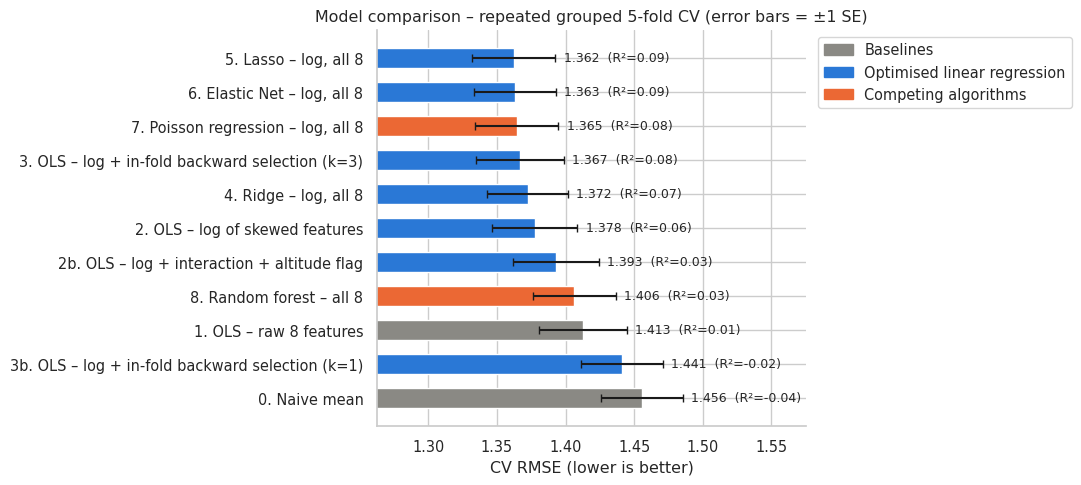

,model,RMSE,SE,MAE,R2
7,"5. Lasso – log, all 8",1.362,0.030,1.061,0.088
8,"6. Elastic Net – log, all 8",1.363,0.030,1.064,0.088
9,"7. Poisson regression – log, all 8",1.365,0.030,1.046,0.081
4,3. OLS – log + in-fold backward selection (k=3),1.367,0.032,1.052,0.083
6,"4. Ridge – log, all 8",1.372,0.029,1.072,0.074
2,2. OLS – log of skewed features,1.378,0.031,1.069,0.062
3,2b. OLS – log + interaction + altitude flag,1.393,0.031,1.077,0.033
10,8. Random forest – all 8,1.406,0.030,1.095,0.027
1,1. OLS – raw 8 features,1.413,0.032,1.078,0.010
5,3b. OLS – log + in-fold backward selection (k=1),1.441,0.030,1.140,-0.020


In [12]:
# Model comparison
res = pd.DataFrame(results).sort_values("RMSE", ascending=False)
colors = [GREY if m[0] in "01" else ORANGE if m[0] in "78" else BLUE for m in res["model"]]
fig, ax = plt.subplots(figsize=(11, 5))
ax.barh(res["model"], res["RMSE"], xerr=res["SE"], color=colors, height=0.6, error_kw={"capsize": 3})
for i, (v, e_, r) in enumerate(zip(res["RMSE"], res["SE"], res["R2"])):
    ax.text(v + e_ + 0.006, i, f"{v:.3f}  (R²={r:.2f})", va="center", fontsize=9)
ax.set(xlim=(res["RMSE"].min() - 0.1, res["RMSE"].max() + 0.12), xlabel="CV RMSE (lower is better)",
       title="Model comparison – repeated grouped 5-fold CV (error bars = ±1 SE)")
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=c) for c in [GREY, BLUE, ORANGE]],
          labels=["Baselines", "Optimised linear regression", "Competing algorithms"], loc="upper left", bbox_to_anchor=(1.01, 1))
plt.tight_layout(); plt.show()
res.sort_values("RMSE").round(3)

**Final model: Lasso on log-transformed features** – best CV error (−3.6% vs raw OLS, R² 0.01 → 0.09) and easiest to interpret. Random forest is worst.

## 5. Final model

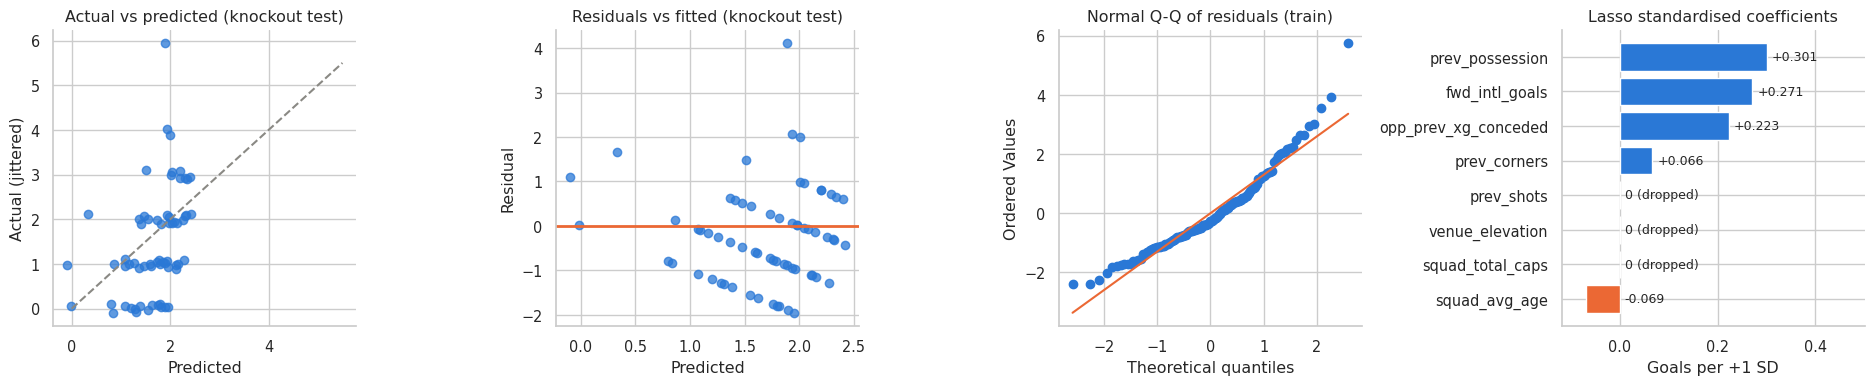

alpha=0.069 | prediction range -0.10-2.42 | Shapiro-Wilk p=0.0000


,model,RMSE,MAE,R2
0,Naive mean,1.212,0.984,-0.001
1,OLS raw (baseline),1.167,0.906,0.072
2,OLS prev_possession only (k=1),1.192,0.939,0.031
3,Lasso + log (final),1.123,0.874,0.140


In [13]:
# Final Lasso model on the knockout test set
final_model = models["5. Lasso – log, all 8"].fit(Xtr_log, y_train)
pred = final_model.predict(Xte_log)
preds = {"Naive mean": np.full(len(y_test), y_train.mean()),
         "OLS raw (baseline)": LinearRegression().fit(X_train, y_train).predict(X_test),
         f"OLS {top1} only (k=1)": LinearRegression().fit(Xtr_log[[top1]], y_train).predict(Xte_log[[top1]]),
         "Lasso + log (final)": pred}
test_tbl = pd.DataFrame([[k, mean_squared_error(y_test, p) ** 0.5, mean_absolute_error(y_test, p), r2_score(y_test, p)]
                         for k, p in preds.items()], columns=["model", "RMSE", "MAE", "R2"])

fig, axes = plt.subplots(1, 4, figsize=(19, 4))
axes[0].scatter(pred, y_test + np.random.default_rng(1).uniform(-.12, .12, len(y_test)), color=BLUE, alpha=.75)
axes[0].plot([0, 5.5], [0, 5.5], "--", color=GREY); axes[0].set(title="Actual vs predicted (knockout test)", xlabel="Predicted", ylabel="Actual (jittered)")
axes[1].scatter(pred, y_test - pred, color=BLUE, alpha=.75); axes[1].axhline(0, color=ORANGE, lw=2)
axes[1].set(title="Residuals vs fitted (knockout test)", xlabel="Predicted", ylabel="Residual")
train_resid = y_train - final_model.predict(Xtr_log)
stats.probplot(train_resid, plot=axes[2]); axes[2].set_title("Normal Q-Q of residuals (train)")
axes[2].get_lines()[0].set_color(BLUE); axes[2].get_lines()[1].set_color(ORANGE)
coefs = pd.Series(final_model[-1].coef_, index=FEATURES).sort_values()
axes[3].barh(coefs.index, coefs, color=[ORANGE if v < 0 else BLUE for v in coefs])
for i, v in enumerate(coefs):
    axes[3].text(max(v, 0) + 0.01, i, "0 (dropped)" if abs(v) < 1e-6 else f"{v:+.3f}", va="center", fontsize=9)
axes[3].set(title="Lasso standardised coefficients", xlabel="Goals per +1 SD", xlim=(min(coefs.min(), 0) - 0.05, coefs.max() + 0.2))
plt.tight_layout(); plt.show()
print(f"alpha={final_model[-1].alpha_:.3f} | prediction range {pred.min():.2f}-{pred.max():.2f} | "
      f"Shapiro-Wilk p={stats.shapiro(train_resid).pvalue:.4f}")
test_tbl.round(3)



## 6. Robustness

In [14]:
# Robustness checks
X_all = log(X)
rows = []
for seed in range(20):
    tr, te = (np.sort(i) for i in next(GroupShuffleSplit(1, test_size=0.2, random_state=seed).split(X, y, match)))
    for name, m, Xu in [("Naive mean", DummyRegressor(), X), ("OLS raw", LinearRegression(), X),
                        ("Lasso + log (final)", models["5. Lasso – log, all 8"], X_all),
                        ("Poisson + log", models["7. Poisson regression – log, all 8"], X_all)]:
        p = m.fit(Xu.iloc[tr], y.iloc[tr]).predict(Xu.iloc[te])
        rows.append([seed, name, mean_squared_error(y.iloc[te], p) ** 0.5])
rand = pd.DataFrame(rows, columns=["seed", "model", "RMSE"])
summary = rand.groupby("model")["RMSE"].agg(["mean", "std", "min", "max"])
summary["wins_vs_OLS_raw"] = [(rand[rand.model == m].RMSE.values < rand[rand.model == "OLS raw"].RMSE.values).sum()
                              for m in summary.index]
print("(a) 20 random grouped hold-outs (21 matches each), test RMSE:")
print(summary.round(3).to_string())

lasso = models["5. Lasso – log, all 8"]
def lasso_cv(Xs, ys, ms):
    return -cross_validate(lasso, Xs, ys, cv=grouped_cv(ms), scoring="neg_root_mean_squared_error")["test_score"].mean()

keep = ~match.isin(df.loc[df["first_match"], "match_id"])
print(f"\n(b) CV RMSE all {len(y)} rows = {lasso_cv(X_all, y, match):.3f} | "
      f"without first-match games ({keep.sum()} rows) = {lasso_cv(X_all[keep], y[keep], match[keep]):.3f}")

(a) 20 random grouped hold-outs (21 matches each), test RMSE:
                      mean    std    min    max  wins_vs_OLS_raw
model                                                           
Lasso + log (final)  1.280  0.125  1.064  1.471               15
Naive mean           1.376  0.149  1.076  1.607                6
OLS raw              1.317  0.107  1.117  1.489                0
Poisson + log        1.277  0.126  1.042  1.454               18

(b) CV RMSE all 208 rows = 1.284 | without first-match games (160 rows) = 1.235



## 7. Conclusion
Lasso with log features is recommended. Possession, forward goals and the opponent's defence matter most; goals in a single match remain hard to predict (R² ≈ 0.1).